<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab4/lab4_1_core_nlp_tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 4.1 – Core NLP tasks: POS tagging, NER, similarity

**Objectives**
- Tag parts of speech and analyse the vocabulary of marketing copy
- Recognize named entities in product descriptions and in legal contracts
- Measure word and document similarity, and build a small product recommender
- Project documents in 2-D with PCA

**Datasets**
- [Nike product descriptions](https://www.kaggle.com/datasets/thedevastator/nike-product-descriptions-and-metadata) (400 products, shipped with the lab in `data/`)
- [Legal contracts](https://huggingface.co/datasets/albertvillanova/legal_contracts) from Hugging Face (a sample of the 12 000 US contracts of the dataset)

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**.
3. When everything runs, follow the *Submission* section at the end.

## Setup

In [1]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [2]:
import os, re, urllib.request, warnings
from collections import Counter, defaultdict
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

nlp = spacy.load("en_core_web_sm")
print(f"spaCy {spacy.__version__} – setup complete")

spaCy 3.8.11 – setup complete


---
# Part A – Nike product descriptions

In [3]:
def local_file(name, lab="lab4"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

nike_df = pd.read_csv(local_file("NikeProductDescriptions.csv"))
print(f"Shape: {nike_df.shape}, columns: {nike_df.columns.tolist()}")
nike_df.head(3)

Shape: (400, 3), columns: ['Title', 'Subtitle', 'Product Description']


,Title,Subtitle,Product Description
0,Nike Air Force 1 '07,Men's Shoes,It doesn't get more legendary than this. Desig...
1,Nike Air Max Dawn SE,Men's Shoes,Find out what moves you with the Air Max Dawn....
2,Nike SB Dunk Low Pro Premium,Skate Shoes,Pack your style—on your feet. Bringing a fresh...


In [4]:
product = nike_df.iloc[0]
print(f"Title:    {product['Title']}\nSubtitle: {product['Subtitle']}\n\n{product['Product Description']}")
nike_descriptions = nike_df["Product Description"].tolist()

Title:    Nike Air Force 1 '07
Subtitle: Men's Shoes

It doesn't get more legendary than this. Designed to turn heads, the Nike Air Force 1 '07 crosses hardwood comfort with off-court flair. Its crisp leather upper looks sleek and fresh, while lustrous Swoosh logos give off an almost iridescent look to add the perfect amount of flash to make you shine. Consider them a slam dunk.


---
# Part B – Part-of-speech (POS) tagging

POS tagging gives each token its grammatical role (noun, verb, adjective...). spaCy provides a coarse tag (`token.pos_`, universal tag set) and a fine-grained one (`token.tag_`, Penn Treebank tag set).

In [5]:
doc = nlp("Nike Air Force 1 shoes provide incredible comfort and stylish design for athletes.")
for token in doc:
    print(f"{token.text:12} | POS: {token.pos_:6} | tag: {token.tag_:4} | lemma: {token.lemma_}")

Nike         | POS: PROPN  | tag: NNP  | lemma: Nike
Air          | POS: PROPN  | tag: NNP  | lemma: Air
Force        | POS: PROPN  | tag: NNP  | lemma: Force
1            | POS: NUM    | tag: CD   | lemma: 1
shoes        | POS: NOUN   | tag: NNS  | lemma: shoe
provide      | POS: VERB   | tag: VBP  | lemma: provide
incredible   | POS: ADJ    | tag: JJ   | lemma: incredible
comfort      | POS: NOUN   | tag: NN   | lemma: comfort
and          | POS: CCONJ  | tag: CC   | lemma: and
stylish      | POS: ADJ    | tag: JJ   | lemma: stylish
design       | POS: NOUN   | tag: NN   | lemma: design
for          | POS: ADP    | tag: IN   | lemma: for
athletes     | POS: NOUN   | tag: NNS  | lemma: athlete
.            | POS: PUNCT  | tag: .    | lemma: .


### Exercise B.1 – POS distribution of the product descriptions

NOUN  :   4620 (20.7%)
VERB  :   2786 (12.5%)
PUNCT :   2694 (12.1%)
ADJ   :   2164 (9.7%)
ADP   :   2152 (9.6%)
DET   :   1943 (8.7%)
PRON  :   1711 (7.7%)
PROPN :   1221 (5.5%)
CCONJ :    741 (3.3%)
AUX   :    661 (3.0%)
ADV   :    641 (2.9%)
PART  :    401 (1.8%)


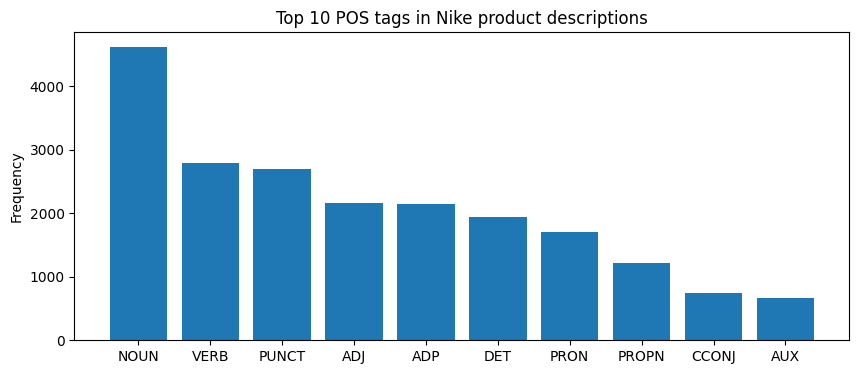

In [6]:
def pos_distribution(texts):
    """Counter of coarse POS tags (token.pos_) over a list of texts."""
    counts = Counter()
    for doc in nlp.pipe(texts):
        counts.update(token.pos_ for token in doc)
    return counts

pos_counts = pos_distribution(nike_descriptions)
total = sum(pos_counts.values())
for pos, count in pos_counts.most_common(12):
    print(f"{pos:6}: {count:6} ({100 * count / total:.1f}%)")
assert pos_counts and pos_counts.most_common(1)[0][0] in ("NOUN", "PUNCT", "ADP", "DET"), "Check that you count token.pos_"

top = dict(pos_counts.most_common(10))
plt.figure(figsize=(10, 4))
plt.bar(top.keys(), top.values())
plt.title("Top 10 POS tags in Nike product descriptions")
plt.ylabel("Frequency")
plt.show()

### Exercise B.2 – Most frequent adjectives and verbs

In [7]:
def top_words_by_pos(texts, pos_tag, top_n=20):
    """(lemma, count) list of the top_n most frequent lowercase lemmas with the given POS tag,
    ignoring stop words and lemmas shorter than 3 characters."""
    counts = Counter()
    for doc in nlp.pipe(texts):
        for token in doc:
            lemma = token.lemma_.lower()
            if token.pos_ == pos_tag and not token.is_stop and len(lemma) >= 3:
                counts[lemma] += 1
    return counts.most_common(top_n)

top_adjectives = top_words_by_pos(nike_descriptions, "ADJ")
top_verbs = top_words_by_pos(nike_descriptions, "VERB")
print("Top adjectives:", top_adjectives)
print("\nTop verbs:     ", top_verbs)
assert len(top_adjectives) == 20 and isinstance(top_adjectives[0], tuple)

Top adjectives: [('soft', 117), ('lightweight', 59), ('favourite', 54), ('cool', 51), ('comfortable', 50), ('classic', 46), ('breathable', 45), ('recycled', 45), ('extra', 39), ('ready', 37), ('dry', 37), ('new', 36), ('stretchy', 35), ('easy', 34), ('fresh', 31), ('iconic', 25), ('smooth', 25), ('good', 24), ('relaxed', 24), ('durable', 20)]

Top verbs:      [('help', 114), ('feel', 72), ('add', 62), ('wicke', 61), ('let', 58), ('stay', 53), ('inspire', 49), ('wear', 41), ('give', 39), ('play', 38), ('bring', 36), ('need', 33), ('design', 31), ('look', 31), ('love', 31), ('pair', 25), ('run', 25), ('come', 24), ('keep', 24), ('find', 23)]


### Question B.3 (written)

1. What do the most frequent adjectives say about Nike's brand message? (3 adjectives, with an interpretation)
2. What do the most frequent verbs say about how the products are positioned? (3 verbs)
3. How does the POS distribution compare with what you would expect in ordinary English text (ratio of nouns / verbs / adjectives)?

<!-- ANSWER lab4.1-B3 -->
**Your answer:**

The most frequent adjectives are *soft* (117), *lightweight* (59) and *comfortable* (50), followed by *classic* (46) and *iconic* (25). The first group sells physical comfort and ease of movement; *classic* and *iconic* sell heritage, so the brand message combines everyday comfort with the status of well-known models. Performance adjectives such as *breathable*, *dry* and *durable*, and *recycled* (45) for sustainability, complete the picture.

The top verbs are *help* (114), *feel* (72) and *stay* (53). *Help* presents the product as a tool that supports the wearer ("helps you stay dry"), *feel* puts the experience of wearing it first, and *stay* ("stay cool", "stay dry") promises a lasting benefit. *Inspire* (49) also links the products to Nike's motivational tone. One lemma is wrong: *wicke* (61) is spaCy's lemma for *wicking*.

Nouns are 20.7% of the tokens, verbs 12.5% and adjectives 9.7%, so there are about 0.78 adjectives per verb. The share of nouns is close to what one would expect in ordinary written English, but adjectives are clearly over-represented: in general text they are usually well below 10% and much rarer than verbs. This matches descriptive marketing copy, which qualifies every product feature.
<!-- END ANSWER -->

---
# Part C – Named entity recognition (NER)

NER finds and classifies mentions of real-world objects: persons, organizations, places, dates, amounts...

In [8]:
doc = nlp("Nike launched Air Jordan in 1984 in Chicago. Michael Jordan wore them throughout his NBA career.")
for ent in doc.ents:
    print(f"{ent.text:20} | {ent.label_:8} | {spacy.explain(ent.label_)}")

Nike                 | ORG      | Companies, agencies, institutions, etc.
Air Jordan           | PERSON   | People, including fictional
1984                 | DATE     | Absolute or relative dates or periods
Chicago              | GPE      | Countries, cities, states
Michael Jordan       | PERSON   | People, including fictional
NBA                  | ORG      | Companies, agencies, institutions, etc.


## C.1 Legal contracts

The contracts are read from the Parquet export of the Hugging Face dataset. Each Parquet *row group* holds 1 000 contracts, so the function below downloads only the first row group (about 20 MB) instead of the whole 220 MB file. A local sample shipped with the lab is used if the download fails.

In [9]:
import fsspec, pyarrow.parquet as pq

def load_legal_contracts(n=50, max_chars=5000):
    """n contracts (truncated to max_chars) from the Hugging Face dataset, or from the local copy."""
    url = "https://huggingface.co/api/datasets/albertvillanova/legal_contracts/parquet/default/train/0.parquet"
    try:
        with fsspec.open(url, "rb") as f:
            df = pq.ParquetFile(f).read_row_group(0).to_pandas()
        print("Loaded from Hugging Face")
    except Exception as e:
        print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
        df = pd.read_csv(local_file("legal_contracts_sample.csv.gz"))
    df = df.head(n).copy()
    df["text"] = df["text"].str[:max_chars]
    return df.reset_index(drop=True)

contracts_df = load_legal_contracts(n=50)
print(f"{len(contracts_df)} contracts")
print(contracts_df.iloc[0]["text"][:600])

Loaded from Hugging Face
50 contracts
QuickLinks -- Click here to rapidly navigate through this document





AMENDED AND RESTATED
EMPLOYMENT AND NONCOMPETITION AGREEMENT

    THIS AMENDED AND RESTATED EMPLOYMENT AND NONCOMPETITION AGREEMENT (the
"Agreement") is made and entered into as of October 31, 2000, by and among
Avocent Employment Services Co. (formerly known as Polycon Investments, Inc.), a
Texas corporation ("Employer"), Avocent Corporation, a Delaware corporation, and
R. Byron Driver (the "Employee").


RECITALS

    WHEREAS, the Employer is a direct or indirect subsidiary of Avocent
Corporation engaged in the business 


### Exercise C.2 – Extract the entities

In [10]:
def extract_entities(texts, entity_types=None):
    """dict {entity label: list of entity texts} over the texts. entity_types=None keeps every label."""
    entities = defaultdict(list)
    for doc in nlp.pipe(texts):
        for ent in doc.ents:
            if entity_types is None or ent.label_ in entity_types:
                entities[ent.label_].append(ent.text)
    return entities

contract_entities = extract_entities(contracts_df["text"].head(10).tolist())
for label, ents in sorted(contract_entities.items()):
    print(f"\n{label} ({len(ents)} mentions): {Counter(ents).most_common(6)}")
assert "ORG" in contract_entities and "DATE" in contract_entities, "Contracts should contain ORG and DATE entities"


CARDINAL (290 mentions): [('12', 9), ('2', 8), ('1', 7), ('26', 7), ('4', 6), ('5', 6)]

DATE (117 mentions): [('October 28, 2000', 7), ('1934', 5), ('annual', 5), ('1998', 4), ('2000', 4), ('2001', 3)]

EVENT (6 mentions): [('Plan', 3), ('THIS SIXTH AMENDMENT TO THIRD AMENDED', 1), ('this "Sixth Amendment', 1), ('Nine Months Ended', 1)]

FAC (7 mentions): [('the Performance\nCycle', 2), ('Sections 2.5', 1), ('Lakeshore Parkway', 1), ('the Effective\nTime of the Merger', 1), ('Plan', 1), ('Bonus', 1)]

GPE (66 mentions): [('Employee', 27), ('Delaware', 4), ('Lender', 4), ('Apex', 3), ('N.A.', 2), ('Michigan', 2)]

LAW (41 mentions): [('Section 7.20', 3), ('the "Agreement"', 2), ('Section 7.09', 2), ('Section 13 or 15(d', 2), ('Section 3', 2), ('Section 2', 2)]

LOC (3 mentions): [('Executive', 3)]

MONEY (31 mentions): [('5,466,316', 2), ('5,098,952', 2), ('5,420,470', 2), ('more than $1 million', 2), ('more than $250,000', 1), ('250,000', 1)]

NORP (2 mentions): [('B.', 1), ('Aspirat

## C.3 Entity types: products vs contracts

             Nike products  Legal contracts
ORG                     44              308
CARDINAL                15              290
DATE                    19              117
GPE                      3               66
LAW                      1               41
PERSON                  21               36
MONEY                    0               31
WORK_OF_ART              0               31
PRODUCT                  5               12
FAC                      0                7
PERCENT                  2                6
EVENT                    2                6
LOC                      0                3
QUANTITY                 2                2
ORDINAL                  6                2
NORP                     2                2
TIME                     0                1


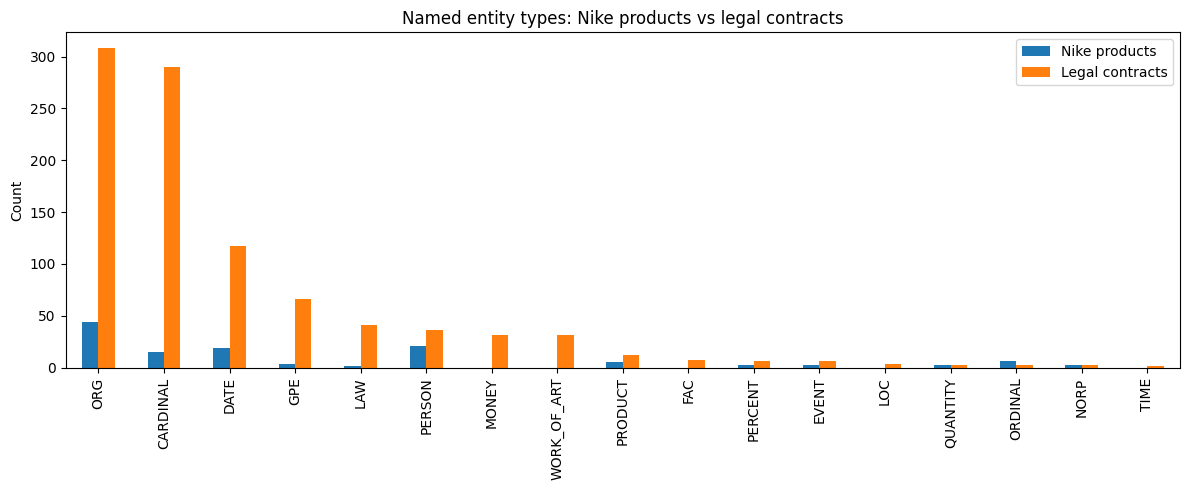

In [11]:
nike_entities = extract_entities(nike_descriptions[:50])

comparison_df = (pd.DataFrame({"Nike products": {k: len(v) for k, v in nike_entities.items()},
                               "Legal contracts": {k: len(v) for k, v in contract_entities.items()}})
                 .fillna(0).astype(int).sort_values("Legal contracts", ascending=False))
print(comparison_df)

comparison_df.plot(kind="bar", figsize=(12, 5))
plt.title("Named entity types: Nike products vs legal contracts")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

### Question C.4 (written)

1. Which entity types dominate in the product descriptions? Why does it make sense?
2. Which entity types dominate in the contracts? Why?
3. Give 2 or 3 entities found in the contracts that you find interesting, and 1 error of the NER model.

<!-- ANSWER lab4.1-C4 -->
**Your answer:**

In the 50 product descriptions, ORG (44), PERSON (21) and DATE (19) dominate. ORG makes sense because the texts are full of brand and technology names (*Nike Air*, *Zoom Air*), and DATE mostly comes from references to the brand's history (*'90s*, *80s*, *35 years*). Most PERSON mentions, however, are model or colour names (*Max Dawn*, *Cement Grey*), not people.

In the 10 contracts, ORG (308), CARDINAL (290) and DATE (117) dominate, followed by GPE (66), LAW (41) and MONEY (31). Contracts name the parties (companies, boards, committees), number their sections and amounts, and fix effective dates and deadlines, so these types are expected.

Interesting entities: *October 28, 2000* (DATE, an effective date that appears 7 times), *more than $1 million* (MONEY, a threshold in a clause), *Section 7.20* (LAW, a cross-reference inside the contract) and *Delaware* (GPE, the state of incorporation). Errors: *Employee* is tagged GPE 27 times, *Unaudited* is tagged PERSON 7 times and the company *Cybex* is tagged PERSON. The `en_core_web_sm` model is trained on general web and news text, so capitalized legal role names and table headers are misread.
<!-- END ANSWER -->

---
# Part D – Word and document similarity

## D.1 Word similarity with pre-trained vectors

`en_core_web_sm` ships no word vectors, so the GloVe vectors of Lab 3.2 are used here (cached by gensim after the first download).

In [12]:
import gensim.downloader as api
glove = api.load("glove-wiki-gigaword-100")

for word in ["running", "comfort", "athletic", "style"]:
    print(f"{word:10} -> {[w for w, s in glove.most_similar(word, topn=6)]}")

running    -> ['ran', 'run', 'line', 'going', 'along', 'out']
comfort    -> ['pleasure', 'sense', 'warmth', 'happiness', 'accommodation', 'feeling']
athletic   -> ['basketball', 'football', 'collegiate', 'sporting', 'sports', 'soccer']
style      -> ['styles', 'inspired', 'modern', 'revival', 'traditional', 'elegant']


### Exercise D.1 – Similarity between pairs of words

In [13]:
pairs = [("shoe", "sneaker"), ("shoe", "contract"), ("comfort", "cushioning"), ("running", "jogging"), ("running", "lawyer")]

pair_similarities = [(a, b, float(glove.similarity(a, b))) for a, b in pairs]

for a, b, s in sorted(pair_similarities, key=lambda t: -t[2]):
    print(f"{a:10} {b:12} {s:.3f}")
assert pair_similarities[0][2] > pair_similarities[1][2], "'shoe' should be closer to 'sneaker' than to 'contract'"

shoe       sneaker      0.620
running    jogging      0.363
shoe       contract     0.329
running    lawyer       0.251
comfort    cushioning   0.198


## D.2 Document similarity: a product recommender

### Exercise D.2

Complete `find_similar_products`: TF-IDF vectors of the descriptions and of the query, cosine similarity, top-n products.

In [14]:
tfidf_products = TfidfVectorizer(stop_words="english").fit(nike_df["Product Description"])
product_vectors = tfidf_products.transform(nike_df["Product Description"])

def find_similar_products(query, top_n=5):
    """DataFrame of the top_n products most similar to the query (columns Title, Subtitle, Similarity)."""
    query_vector = tfidf_products.transform([query])
    scores = cosine_similarity(query_vector, product_vectors).ravel()
    top_indices = np.argsort(scores)[::-1][:top_n]
    result = nike_df.iloc[top_indices][["Title", "Subtitle"]].copy()
    result["Similarity"] = scores[top_indices]
    return result.reset_index(drop=True)

queries = ["I want comfortable running shoes for long distance training",
           "Looking for stylish basketball shoes with great cushioning",
           "Need shoes for the gym and weight training"]
for query in queries:
    print(f"\nQuery: '{query}'")
    print(find_similar_products(query).to_string(index=False))

res = find_similar_products(queries[1])
assert list(res.columns) == ["Title", "Subtitle", "Similarity"] and len(res) == 5
assert res["Similarity"].is_monotonic_decreasing, "Results must be sorted by decreasing similarity"


Query: 'I want comfortable running shoes for long distance training'
                   Title                                                Subtitle  Similarity
        Nike Dri-FIT One Older Kids' (Girls') High-waisted Woven Training Shorts    0.267717
      Nike 'Just Do It.'                               Men's Long-Sleeve T-Shirt    0.232396
Nike Zoom Rival Waffle 5                               Athletics Distance Spikes    0.232270
         Nike Alphafly 2                               Women's Road Racing Shoes    0.189577
         Nike Alphafly 2                                 Men's Road Racing Shoes    0.133890

Query: 'Looking for stylish basketball shoes with great cushioning'
                          Title                            Subtitle  Similarity
            Paris Saint-Germain               Men's Fleece Trousers    0.151518
       Nike Air Deldon "Legacy"        Easy On/Off Basketball Shoes    0.143465
                  Kylian Mbappé Older Kids' Dri-FIT Football Sh

### Exercise D.3 – Your own query

In [15]:
my_query = "lightweight breathable shoes for trail running"
print(f"Query: '{my_query}'")
print(find_similar_products(my_query).to_string(index=False))

Query: 'lightweight breathable shoes for trail running'
                  Title                                                Subtitle  Similarity
       Nike Dri-FIT One Older Kids' (Girls') High-waisted Woven Training Shorts    0.346976
        Nike Alphafly 2                               Women's Road Racing Shoes    0.170719
        Nike Challenger                     Older Kids' (Boys') Training Shorts    0.157601
Nike Dri-FIT Swoosh Fly                            Women's Short-Sleeve T-Shirt    0.156564
           Nike Dri-FIT                                Women's Running Trousers    0.151620


### Question D.4 (written)

1. For your query, are the top 3 products relevant? Why / why not?
2. Are the similarity scores high or low? What does it mean?
3. Compare the results of the "running" and "basketball" queries.
4. Give 2 limits of this TF-IDF approach.

<!-- ANSWER lab4.1-D4 -->
**Your answer:**

For my query, *lightweight breathable shoes for trail running*, only the second result (*Nike Alphafly 2*, women's road racing shoes) is relevant. The first is a pair of girls' training shorts (0.347), because its description repeats *running* three times and also contains *lightweight* and *breathable*. The third is another pair of training shorts. No description contains *trail* in a matching context, and *shoes* is a weak signal because the product type is in the subtitle, not in the description used for the vectors.

The scores are low, between 0.13 and 0.35. The query has only a few words, and a product scores highly as soon as it repeats one of them, so the score measures word overlap rather than how well the product meets the need.

The running query works better than the basketball query. It returns two relevant running products (*Zoom Rival Waffle 5* distance spikes and *Alphafly 2*) in positions 3–5, after shorts and a T-shirt that also mention running. The basketball query returns only one basketball shoe (*Air Deldon*, rank 2); the top result is a pair of Paris Saint-Germain trousers, matched only on the word *stylish*.

Two limits: (1) TF-IDF matches exact words only, so synonyms (*sneaker* / *shoe*, *jogging* / *running*) and meaning are ignored; (2) it gives no weight to which words matter for the user's need, so a generic word such as *stylish* can outrank the product type. Using the subtitle in the text, or embeddings, would address part of this.
<!-- END ANSWER -->

---
# Part E – Dimensionality reduction with PCA

The product subtitles are very detailed (more than 200 distinct values). A coarse category is derived from them to colour the plots.

In [16]:
def coarse_category(subtitle):
    s = str(subtitle).lower()
    for key in ["shoes", "t-shirt", "shorts", "hoodie", "jacket", "trousers", "pants", "leggings", "socks", "bra", "tank", "jersey", "top", "dress"]:
        if key in s:
            return key
    return "other"

nike_df["Category"] = nike_df["Subtitle"].apply(coarse_category)
print(nike_df["Category"].value_counts())

Category
shoes       117
t-shirt      61
other        47
shorts       45
top          27
trousers     25
leggings     24
jacket       16
hoodie       13
tank         11
bra           6
socks         5
jersey        1
pants         1
dress         1
Name: count, dtype: int64


## E.1 Products in 2-D

Explained variance: PC1 3.7%, PC2 2.5%


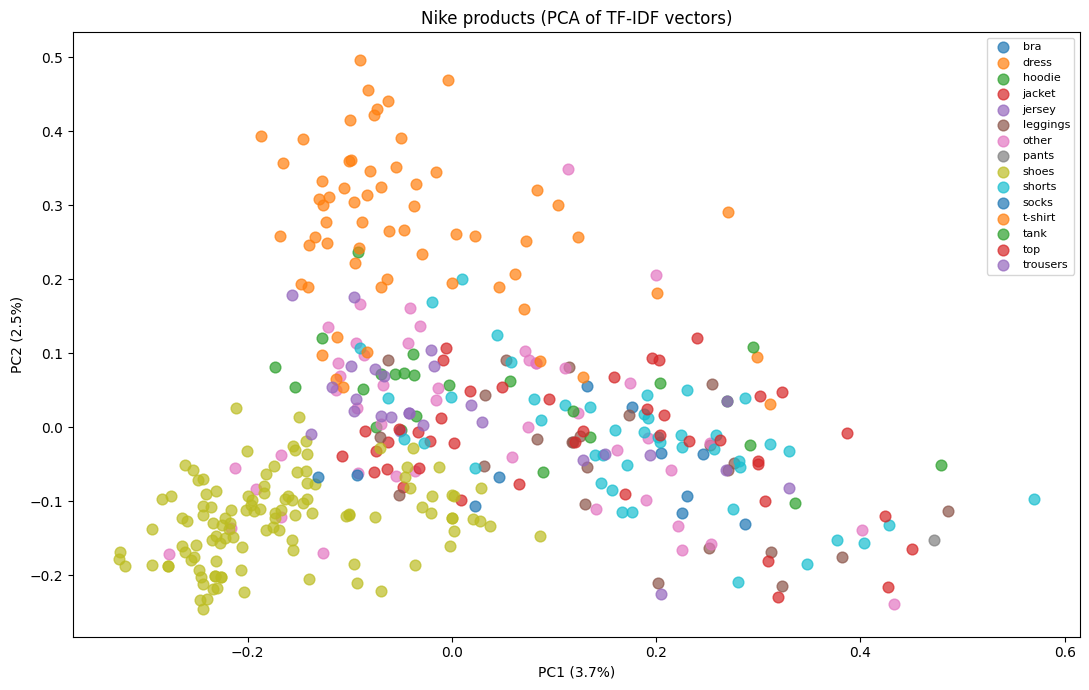

In [17]:
tfidf_pca = TfidfVectorizer(max_features=300, stop_words="english")
X = tfidf_pca.fit_transform(nike_df["Product Description"]).toarray()

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X)
print(f"Explained variance: PC1 {pca.explained_variance_ratio_[0]:.1%}, PC2 {pca.explained_variance_ratio_[1]:.1%}")

pca_df = pd.DataFrame({"PC1": coords[:, 0], "PC2": coords[:, 1], "Title": nike_df["Title"], "Category": nike_df["Category"]})
plt.figure(figsize=(11, 7))
for category, group in pca_df.groupby("Category"):
    plt.scatter(group["PC1"], group["PC2"], label=category, alpha=0.7, s=60)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.title("Nike products (PCA of TF-IDF vectors)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## E.2 Neighbours in the PCA space

In [18]:
def neighbours_in_pca_space(product_index, n_neighbors=5):
    """n_neighbors closest products (Euclidean distance on PC1, PC2)."""
    ref = coords[product_index]
    distances = np.linalg.norm(coords - ref, axis=1)
    distances[product_index] = np.inf
    idx = distances.argsort()[:n_neighbors]
    out = pca_df.iloc[idx][["Title", "Category"]].copy()
    out["Distance"] = distances[idx].round(3)
    return out

for idx in [0, 10, 20]:
    print(f"\nReference: {pca_df.iloc[idx]['Title']} ({pca_df.iloc[idx]['Category']})")
    print(neighbours_in_pca_space(idx).to_string(index=False))


Reference: Nike Air Force 1 '07 (shoes)
                     Title Category  Distance
Air Jordan 1 Retro High OG    shoes     0.011
    Nike Dunk High Premium    shoes     0.022
       Nike Blazer Low '77    shoes     0.022
   Nike Air Force 1 Sculpt    shoes     0.024
          Air Jordan 1 Mid    shoes     0.024

Reference: Air Jordan XXXVII Low PF (shoes)
                           Title Category  Distance
            Jordan Why Not .6 PF    shoes     0.001
NikeCourt Zoom Vapor Cage 4 Rafa    shoes     0.003
Nike Air Force 1 '07 Next Nature    shoes     0.025
                Nike AF-1 Shadow    shoes     0.036
                   Nike SB Shane    shoes     0.047

Reference: Nike E-Series 1.0 (shoes)
               Title Category  Distance
Nike Air Max Dawn SE    shoes     0.006
    Nike SB Force 58    other     0.012
Nike Air Force 1 '07    shoes     0.012
Nike Air Force 1 '07    shoes     0.017
Nike Air Force 1 '07    shoes     0.018


### Exercise E.3 – Products and contracts in the same space

Combine 30 product descriptions and 30 contracts (first 1 000 characters), vectorize them together, apply PCA and plot the two groups with different colours.

Explained variance: 9.0%


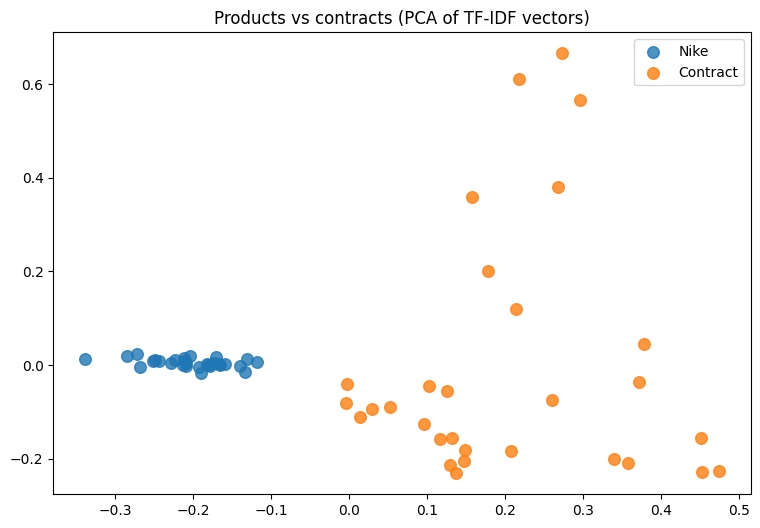

In [19]:
nike_sample = nike_df.sample(n=30, random_state=42)["Product Description"].tolist()
contract_sample = contracts_df.sample(n=30, random_state=42)["text"].str[:1000].tolist()
all_texts = nike_sample + contract_sample
groups = ["Nike"] * 30 + ["Contract"] * 30

X_all = TfidfVectorizer(stop_words="english").fit_transform(all_texts).toarray()
pca_all = PCA(n_components=2, random_state=42)
coords_all = pca_all.fit_transform(X_all)

print(f"Explained variance: {pca_all.explained_variance_ratio_.sum():.1%}")
plt.figure(figsize=(9, 6))
for g in ["Nike", "Contract"]:
    mask = np.array(groups) == g
    plt.scatter(coords_all[mask, 0], coords_all[mask, 1], label=g, s=70, alpha=0.8)
plt.legend()
plt.title("Products vs contracts (PCA of TF-IDF vectors)")
plt.show()
assert coords_all.shape == (60, 2)

### Question E.4 (written)

1. Nike plot: do similar product types group together? What could the two axes represent?
2. Combined plot: are the two corpora separated? Are some products close to contracts, and why?
3. How much variance do the two components explain in each case? What does it say about the quality of the 2-D picture?

<!-- ANSWER lab4.1-E4 -->
**Your answer:**

Product types partly group together. Shoes form a clear cluster on the left (negative PC1), and T-shirts form a cluster at the top (high PC2); shorts, tops, jackets and leggings overlap on the right. PC1 opposes footwear vocabulary (*air*, *leather*, *classic*, *cushioning*, *skate*) to technical apparel vocabulary (*wicking*, *recycled*, *polyester*, *fabric*, *sweat*). PC2 opposes casual cotton T-shirt words (*tee*, *cotton*, *relaxed*, *roomy*, *graphics*) to performance words (*recycled*, *polyester*, *cushioning*). The colour palette repeats after ten categories, so *dress* and *t-shirt* share the same colour; the top cluster is mainly the 61 T-shirts.

In the combined plot, the two corpora are clearly separated: the 30 Nike descriptions form a tight group at negative PC1, and the 30 contracts are spread over positive PC1. No product is close to the contracts, because the two corpora share almost no vocabulary. The contracts are spread out along PC2 because they come from different contract types (employment, credit, trust).

The two components explain only 6.2% of the variance for the Nike products (3.7% + 2.5%) and 9.0% for the combined corpus. The 2-D picture is therefore a rough view: it shows the main contrasts, but most of the information is lost, and distances in the plot (as in E.2) should not be read as precise similarities.
<!-- END ANSWER -->

---
# Part F – Bonus: dependency parsing

The dependency parser links each token to its syntactic head. `displacy` draws the tree.

In [20]:
from spacy import displacy

sentence = nike_descriptions[0].split(".")[0] + "."
doc = nlp(sentence)
displacy.render(doc, style="dep", jupyter=True, options={"compact": True, "distance": 90})

for token in doc:
    print(f"{token.text:12} | head: {token.head.text:12} | dep: {token.dep_:10} | POS: {token.pos_}")

It           | head: get          | dep: nsubj      | POS: PRON
does         | head: get          | dep: aux        | POS: AUX
n't          | head: get          | dep: neg        | POS: PART
get          | head: get          | dep: ROOT       | POS: VERB
more         | head: legendary    | dep: advmod     | POS: ADV
legendary    | head: get          | dep: acomp      | POS: ADJ
than         | head: legendary    | dep: prep       | POS: ADP
this         | head: than         | dep: pobj       | POS: PRON
.            | head: get          | dep: punct      | POS: PUNCT


**Bonus exercise:** pick a sentence from a contract, parse it and identify the root verb, its subject (`nsubj`) and its object (`dobj`).

In [21]:
contract_doc = nlp(contracts_df.iloc[0]["text"])
sentence = next(
    sent for sent in contract_doc.sents
    if {"nsubj", "dobj"} <= {child.dep_ for child in sent.root.children}
    and not sent.text.isupper() and len(sent) >= 8
)
root = sentence.root
subjects = [child.text for child in root.children if child.dep_ == "nsubj"]
objects = [child.text for child in root.children if child.dep_ == "dobj"]

print(" ".join(sentence.text.split()))
print(f"\nRoot verb: {root.text} | subject (nsubj): {subjects} | object (dobj): {objects}")

The Employee shall devote such of his business time, energy, and skill to the affairs of Avocent and Employer as shall be necessary to perform the duties of Senior Vice President of Operations and Chief Operating Officer.

Root verb: devote | subject (nsubj): ['Employee'] | object (dobj): ['such']


---
## Summary

- POS tagging characterizes the style of a corpus (adjective-heavy marketing copy).
- NER extracts organizations, dates, amounts; its errors depend on the domain of the model.
- TF-IDF + cosine similarity gives a working recommender in a few lines, limited to lexical matching.
- PCA gives a quick 2-D picture of a corpus, at the cost of most of the variance.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.